<a href="https://colab.research.google.com/github/PabloShol/simulacion2/blob/main/Integral_Estocastica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integral estocástica: $\int_0^t B_s^2\,ds$
$B_s$ es un movimiento browniano. Esta integral es **aleatoria**: cada trayectoria de $B$ da un número distinto.
Por eso no buscamos "un número", sino su **distribución**: media, varianza, histograma.

**Resultados teóricos que vamos a verificar:**
- $E\left[\int_0^t B_s^2 ds\right] = \dfrac{t^2}{2}$  (porque $E[B_s^2]=s$)
- $Var\left[\int_0^t B_s^2 ds\right] = \dfrac{t^4}{3}$
- Por la fórmula de Itô: $\int_0^t B_s^2 ds = t\,B_t^2 - 2\int_0^t s\,B_s\,dB_s - \dfrac{t^2}{2}$

## 1. Librerías y parámetros

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)      # para que los resultados se repitan

t = 1.0                 # tiempo final
n = 1000                # número de pasos en el tiempo
M = 10000               # número de trayectorias (simulaciones)
dt = t / n              # tamaño de cada paso

## 2. Simular el movimiento browniano
Cada incremento $\Delta B \sim N(0, dt)$. Sumándolos (cumsum) obtenemos la trayectoria. Empieza en $B_0=0$.

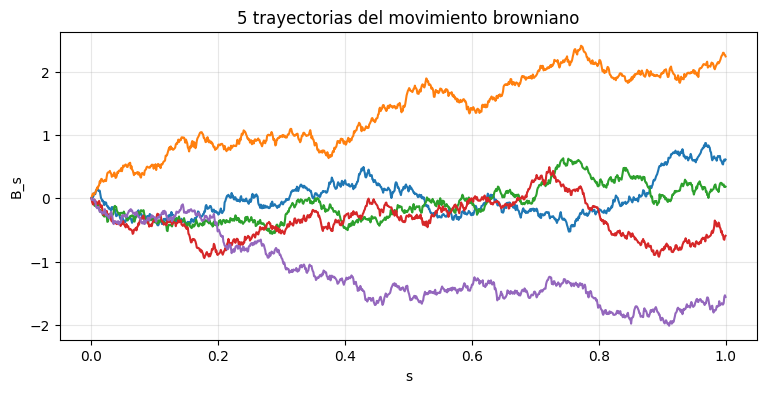

In [2]:
dB = np.random.normal(0, np.sqrt(dt), size=(M, n))          # incrementos
B = np.hstack([np.zeros((M, 1)), np.cumsum(dB, axis=1)])    # trayectorias, B_0 = 0
s = np.linspace(0, t, n + 1)                                 # malla de tiempos

# Ver 5 trayectorias
plt.figure(figsize=(9, 4))
for i in range(5):
    plt.plot(s, B[i])
plt.title("5 trayectorias del movimiento browniano")
plt.xlabel("s"); plt.ylabel("B_s"); plt.grid(alpha=0.3)
plt.show()

## 3. Calcular la integral (suma de Riemann)
$\int_0^t B_s^2 ds \approx \sum_{k} B_{s_k}^2\,\Delta s$. Usamos la regla del trapecio, que es más precisa.

In [3]:
integral = np.trapz(B**2, s, axis=1) if hasattr(np, "trapz") else np.trapezoid(B**2, s, axis=1)
print("Ejemplo: valor de la integral en las primeras 5 trayectorias:")
print(np.round(integral[:5], 4))

Ejemplo: valor de la integral en las primeras 5 trayectorias:
[0.0912 2.2367 0.0851 0.2104 1.6961]


## 4. Comparar simulación vs. teoría

In [4]:
media_sim = integral.mean()
var_sim   = integral.var()
media_teo = t**2 / 2
var_teo   = t**4 / 3

print(f"Media    simulada: {media_sim:.4f}   teórica: {media_teo:.4f}")
print(f"Varianza simulada: {var_sim:.4f}   teórica: {var_teo:.4f}")

Media    simulada: 0.4958   teórica: 0.5000
Varianza simulada: 0.3231   teórica: 0.3333


## 5. Distribución de la integral

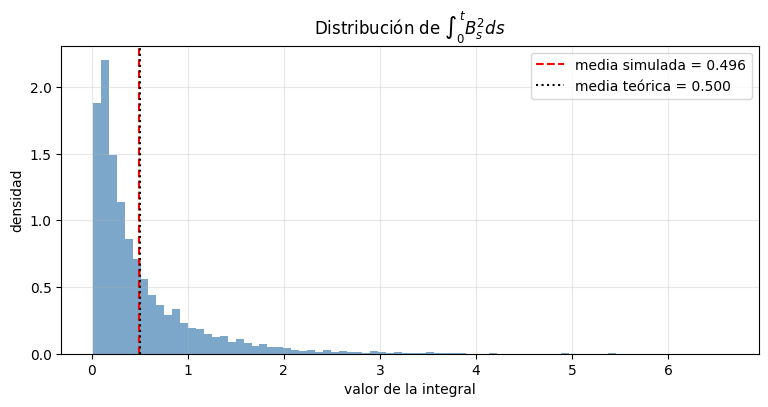

In [5]:
plt.figure(figsize=(9, 4))
plt.hist(integral, bins=80, density=True, alpha=0.7, color="steelblue")
plt.axvline(media_sim, color="red", ls="--", label=f"media simulada = {media_sim:.3f}")
plt.axvline(media_teo, color="black", ls=":", label=f"media teórica = {media_teo:.3f}")
plt.title(r"Distribución de $\int_0^t B_s^2 ds$")
plt.xlabel("valor de la integral"); plt.ylabel("densidad")
plt.legend(); plt.grid(alpha=0.3)
plt.show()
# Ojo: NO es normal. Es asimétrica a la derecha y siempre positiva (B^2 >= 0).

## 6. Verificación con la fórmula de Itô
$\int_0^t B_s^2 ds = t B_t^2 - 2\int_0^t s B_s\,dB_s - \dfrac{t^2}{2}$

La integral de Itô se evalúa en el **punto izquierdo** de cada intervalo: $\sum s_k B_{s_k}\,\Delta B_k$.

In [6]:
ito = np.sum(s[:-1] * B[:, :-1] * dB, axis=1)       # ∫ s B_s dB_s (punto izquierdo)
lado_derecho = t * B[:, -1]**2 - 2 * ito - t**2 / 2

print("Riemann (directa):", np.round(integral[:5], 4))
print("Vía fórmula de Itô:", np.round(lado_derecho[:5], 4))
print(f"Error promedio entre ambos métodos: {np.mean(np.abs(integral - lado_derecho)):.5f}")

Riemann (directa): [0.0912 2.2367 0.0851 0.2104 1.6961]
Vía fórmula de Itô: [0.0732 2.2295 0.0762 0.233  1.6947]
Error promedio entre ambos métodos: 0.02053


## 7. ¿Cómo cambia con t? (la media crece como t²/2)

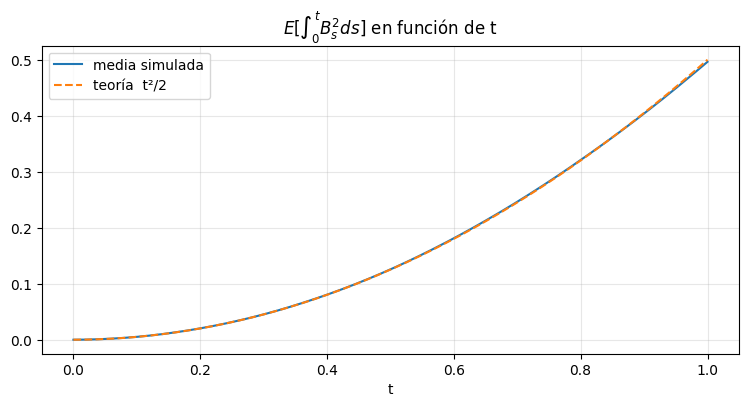

In [7]:
tiempos = s[1:]
media_por_t = np.cumsum((B[:, 1:]**2) * dt, axis=1).mean(axis=0)

plt.figure(figsize=(9, 4))
plt.plot(tiempos, media_por_t, label="media simulada")
plt.plot(tiempos, tiempos**2 / 2, "--", label="teoría  t²/2")
plt.title(r"$E[\int_0^t B_s^2 ds]$ en función de t")
plt.xlabel("t"); plt.legend(); plt.grid(alpha=0.3)
plt.show()